## Human Action Detection 

## Step 1 : Import Libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
from sklearn.utils import resample
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import statsmodels.api as sm

In [8]:
from sklearn.metrics import classification_report, r2_score, accuracy_score, recall_score,\
precision_score, f1_score, confusion_matrix, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

In [31]:
import os

print(os.getcwd())


C:\Users\LENOVO\Human Action


In [8]:
import pandas as pd

df = pd.read_csv("data/mHealth_subject1.csv")

df.head()

,acceleration from the chest sensor (X axis),acceleration from the chest sensor (Y axis),acceleration from the chest sensor (Z axis),electrocardiogram signal (lead 1),electrocardiogram signal (lead 2),acceleration from the left-ankle sensor (X axis),acceleration from the left-ankle sensor (Y axis),acceleration from the left-ankle sensor (Z axis),gyro from the left-ankle sensor (X axis),gyro from the left-ankle sensor (Y axis),...,acceleration from the right-lower-arm sensor (X axis),acceleration from the right-lower-arm sensor (Y axis),acceleration from the right-lower-arm sensor (Z axis),gyro from the right-lower-arm sensor (X axis),gyro from the right-lower-arm sensor (Y axis),gyro from the right-lower-arm sensor (Z axis),magnetometer from the right-lower-arm sensor (X axis),magnetometer from the right-lower-arm sensor (Y axis),magnetometer from the right-lower-arm sensor (Z axis),Label
0,-9.8184,0.009971,0.29563,0.004186,0.004186,2.1849,-9.6967,0.63077,0.103900,-0.84053,...,-8.6499,-4.5781,0.187760,-0.44902,-1.0103,0.034483,-2.35000,-1.610200,-0.030899,0.0
1,-9.8489,0.524040,0.37348,0.004186,0.016745,2.3876,-9.5080,0.68389,0.085343,-0.83865,...,-8.6275,-4.3198,0.023595,-0.44902,-1.0103,0.034483,-2.16320,-0.882540,0.326570,0.0
2,-9.6602,0.181850,0.43742,0.016745,0.037677,2.4086,-9.5674,0.68113,0.085343,-0.83865,...,-8.5055,-4.2772,0.275720,-0.44902,-1.0103,0.034483,-1.61750,-0.165620,-0.030693,0.0
3,-9.6507,0.214220,0.24033,0.079540,0.117220,2.1814,-9.4301,0.55031,0.085343,-0.83865,...,-8.6279,-4.3163,0.367520,-0.45686,-1.0082,0.025862,-1.07710,0.006945,-0.382620,0.0
4,-9.7030,0.303890,0.31156,0.221870,0.205130,2.4173,-9.3889,0.71098,0.085343,-0.83865,...,-8.7008,-4.1459,0.407290,-0.45686,-1.0082,0.025862,-0.53684,0.175900,-1.095500,0.0


In [7]:
df.shape

(161281, 24)

In [8]:
df.head()

,acceleration from the chest sensor (X axis),acceleration from the chest sensor (Y axis),acceleration from the chest sensor (Z axis),electrocardiogram signal (lead 1),electrocardiogram signal (lead 2),acceleration from the left-ankle sensor (X axis),acceleration from the left-ankle sensor (Y axis),acceleration from the left-ankle sensor (Z axis),gyro from the left-ankle sensor (X axis),gyro from the left-ankle sensor (Y axis),...,acceleration from the right-lower-arm sensor (X axis),acceleration from the right-lower-arm sensor (Y axis),acceleration from the right-lower-arm sensor (Z axis),gyro from the right-lower-arm sensor (X axis),gyro from the right-lower-arm sensor (Y axis),gyro from the right-lower-arm sensor (Z axis),magnetometer from the right-lower-arm sensor (X axis),magnetometer from the right-lower-arm sensor (Y axis),magnetometer from the right-lower-arm sensor (Z axis),Label
0,-9.8184,0.009971,0.29563,0.004186,0.004186,2.1849,-9.6967,0.63077,0.103900,-0.84053,...,-8.6499,-4.5781,0.187760,-0.44902,-1.0103,0.034483,-2.35000,-1.610200,-0.030899,0.0
1,-9.8489,0.524040,0.37348,0.004186,0.016745,2.3876,-9.5080,0.68389,0.085343,-0.83865,...,-8.6275,-4.3198,0.023595,-0.44902,-1.0103,0.034483,-2.16320,-0.882540,0.326570,0.0
2,-9.6602,0.181850,0.43742,0.016745,0.037677,2.4086,-9.5674,0.68113,0.085343,-0.83865,...,-8.5055,-4.2772,0.275720,-0.44902,-1.0103,0.034483,-1.61750,-0.165620,-0.030693,0.0
3,-9.6507,0.214220,0.24033,0.079540,0.117220,2.1814,-9.4301,0.55031,0.085343,-0.83865,...,-8.6279,-4.3163,0.367520,-0.45686,-1.0082,0.025862,-1.07710,0.006945,-0.382620,0.0
4,-9.7030,0.303890,0.31156,0.221870,0.205130,2.4173,-9.3889,0.71098,0.085343,-0.83865,...,-8.7008,-4.1459,0.407290,-0.45686,-1.0082,0.025862,-0.53684,0.175900,-1.095500,0.0


In [9]:
print(df.columns.tolist())

['acceleration from the chest sensor (X axis)', 'acceleration from the chest sensor (Y axis)', 'acceleration from the chest sensor (Z axis)', 'electrocardiogram signal (lead 1)', 'electrocardiogram signal (lead 2)', 'acceleration from the left-ankle sensor (X axis)', 'acceleration from the left-ankle sensor (Y axis)', 'acceleration from the left-ankle sensor (Z axis)', 'gyro from the left-ankle sensor (X axis)', 'gyro from the left-ankle sensor (Y axis)', 'gyro from the left-ankle sensor (Z axis)', 'magnetometer from the left-ankle sensor (X axis)', 'magnetometer from the left-ankle sensor (Y axis)', 'magnetometer from the left-ankle sensor (Z axis)', 'acceleration from the right-lower-arm sensor (X axis)', 'acceleration from the right-lower-arm sensor (Y axis)', 'acceleration from the right-lower-arm sensor (Z axis)', 'gyro from the right-lower-arm sensor (X axis)', 'gyro from the right-lower-arm sensor (Y axis)', 'gyro from the right-lower-arm sensor (Z axis)', 'magnetometer from the

In [10]:
df["Label"].value_counts()

Label
0.0     126106
8.0       3379
1.0       3072
3.0       3072
2.0       3072
4.0       3072
6.0       3072
7.0       3072
9.0       3072
10.0      3072
11.0      3072
5.0       3072
12.0      1075
Name: count, dtype: int64

In [11]:
df = pd.read_csv("data/mHealth_subject1.csv")

## Step 2 : Data Importing & Analysis

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161281 entries, 0 to 161280
Data columns (total 24 columns):
 #   Column                                                 Non-Null Count   Dtype  
---  ------                                                 --------------   -----  
 0   acceleration from the chest sensor (X axis)            161280 non-null  float64
 1   acceleration from the chest sensor (Y axis)            161280 non-null  float64
 2   acceleration from the chest sensor (Z axis)            161280 non-null  float64
 3   electrocardiogram signal (lead 1)                      161280 non-null  float64
 4   electrocardiogram signal (lead 2)                      161280 non-null  float64
 5   acceleration from the left-ankle sensor (X axis)       161280 non-null  float64
 6   acceleration from the left-ankle sensor (Y axis)       161280 non-null  float64
 7   acceleration from the left-ankle sensor (Z axis)       161280 non-null  float64
 8   gyro from the left-ankle sensor (X

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
acceleration from the chest sensor (X axis),161280.0,-8.737671,3.806288,-22.3030,-9.832900,-9.330700,-8.020800,18.9600
acceleration from the chest sensor (Y axis),161280.0,0.186275,1.453274,-17.4300,-0.380692,0.252830,0.770090,20.7130
acceleration from the chest sensor (Z axis),161280.0,-0.645707,3.740042,-17.9060,-2.824350,-0.316040,1.665425,24.0840
electrocardiogram signal (lead 1),161280.0,-0.007960,0.504334,-7.3218,-0.188380,-0.025118,0.154890,5.4505
electrocardiogram signal (lead 2),161280.0,-0.035226,0.643813,-8.6196,-0.205130,-0.025118,0.163270,8.5191
acceleration from the left-ankle sensor (X axis),161280.0,1.229914,4.671081,-22.0750,0.095848,1.785900,2.643100,20.0540
acceleration from the left-ankle sensor (Y axis),161280.0,-9.667029,4.064311,-19.6190,-10.066000,-9.570500,-9.025600,21.1610
acceleration from the left-ankle sensor (Z axis),161280.0,-1.650613,5.030605,-19.3730,-3.288900,-0.711750,0.649125,25.0150
gyro from the left-ankle sensor (X axis),161280.0,0.010649,0.495378,-1.5492,-0.372910,-0.161410,0.500930,1.8701
gyro from the left-ankle sensor (Y axis),161280.0,-0.663745,0.322115,-2.1895,-0.848030,-0.741090,-0.596620,1.5253


In [14]:
df.isnull().sum()

acceleration from the chest sensor (X axis)              1
acceleration from the chest sensor (Y axis)              1
acceleration from the chest sensor (Z axis)              1
electrocardiogram signal (lead 1)                        1
electrocardiogram signal (lead 2)                        1
acceleration from the left-ankle sensor (X axis)         1
acceleration from the left-ankle sensor (Y axis)         1
acceleration from the left-ankle sensor (Z axis)         1
gyro from the left-ankle sensor (X axis)                 1
gyro from the left-ankle sensor (Y axis)                 1
gyro from the left-ankle sensor (Z axis)                 1
magnetometer from the left-ankle sensor (X axis)         1
magnetometer from the left-ankle sensor (Y axis)         1
magnetometer from the left-ankle sensor (Z axis)         1
acceleration from the right-lower-arm sensor (X axis)    1
acceleration from the right-lower-arm sensor (Y axis)    1
acceleration from the right-lower-arm sensor (Z axis)   

In [15]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='Label'>

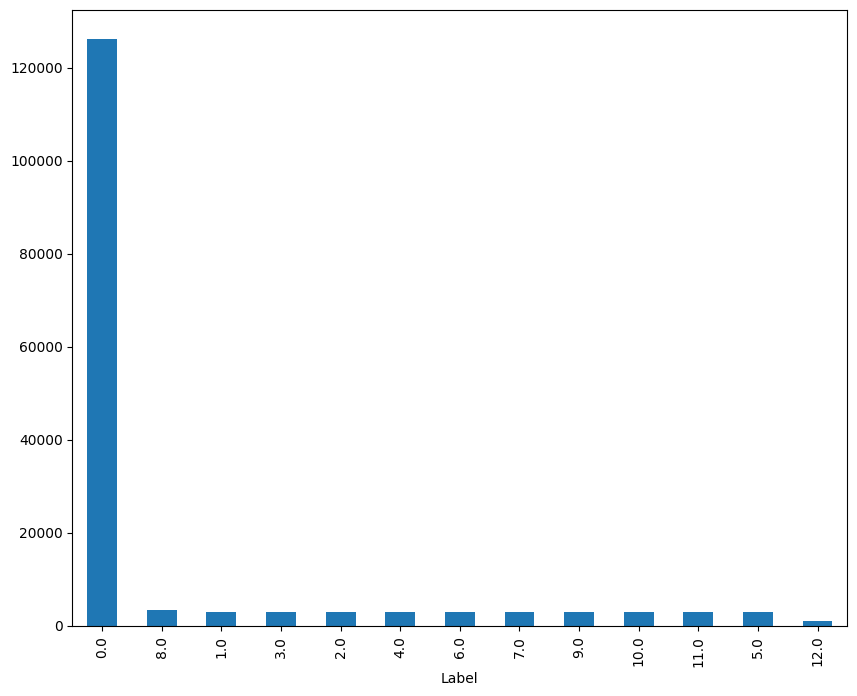

In [16]:
plt.figure(figsize=(10,8))
df['Label'].value_counts().plot.bar()

In [18]:
data_activity_0= df[df["Label"] == 0]
data_activity_else = df[df["Label"] != 0]

In [19]:
data_activity_0=data_activity_0.sample(n=40000) 
df=pd.concat([data_activity_0, data_activity_else])

<Axes: xlabel='Label'>

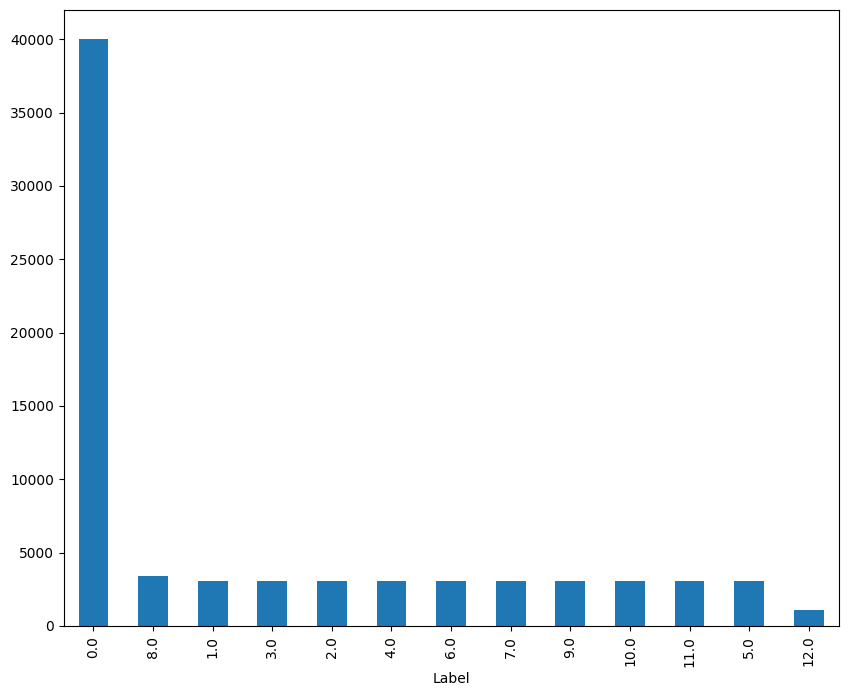

In [21]:
plt.figure(figsize=(10,8))
df['Label'].value_counts().plot.bar()

In [22]:
len(df)

75175

## Step 3:EDA

In [2]:
activity_label= {
0: "None",
1: "Standing still (1 min)",
2: "Sitting and relaxing (1 min)",
3: "Lying down (1 min)",
4: "Walking (1 min)",
5: "Climbing stairs (1 min)",
6: "Waist bends forward (20x)",
7: "Frontal elevation of arms (20x)",
8: "Knees bending (crouching) (20x)",
9: "Cycling (1 min)",
10: "Jogging (1 min)",
11: "Running (1 min)",
12: "Jump front & back (20x)"
}

In [11]:
import pandas as pd

df = pd.read_csv("data/mHealth_subject1.csv")

df["Label"].head()

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: Label, dtype: float64

In [12]:
df['Label']=df['Label'].replace(
[0,1,2,3,4,5,6,7,8,9,10,11,12],
['None',
 'Standing still (1 min)',
 'Sitting and relaxing (1 min)',
 'Lying down (1 min)',
 'Walking (1 min)',
 'Climbing stairs (1 min)',
 'Waist bends forward (20x)',
 'Frontal elevation of arms (20x)',
 'Knees bending (crouching) (20x)',
 'Cycling (1 min)',
 'Jogging (1 min)',
 'Running (1 min)',
 'Jump front & back (20x)']
)

In [13]:
df["Label"]

0         None
1         None
2         None
3         None
4         None
          ... 
161276    None
161277    None
161278    None
161279    None
161280     NaN
Name: Label, Length: 161281, dtype: object

In [14]:
df.Label.value_counts()

Label
None                               126106
Knees bending (crouching) (20x)      3379
Standing still (1 min)               3072
Lying down (1 min)                   3072
Sitting and relaxing (1 min)         3072
Walking (1 min)                      3072
Waist bends forward (20x)            3072
Frontal elevation of arms (20x)      3072
Cycling (1 min)                      3072
Jogging (1 min)                      3072
Running (1 min)                      3072
Climbing stairs (1 min)              3072
Jump front & back (20x)              1075
Name: count, dtype: int64

<Axes: ylabel='count'>

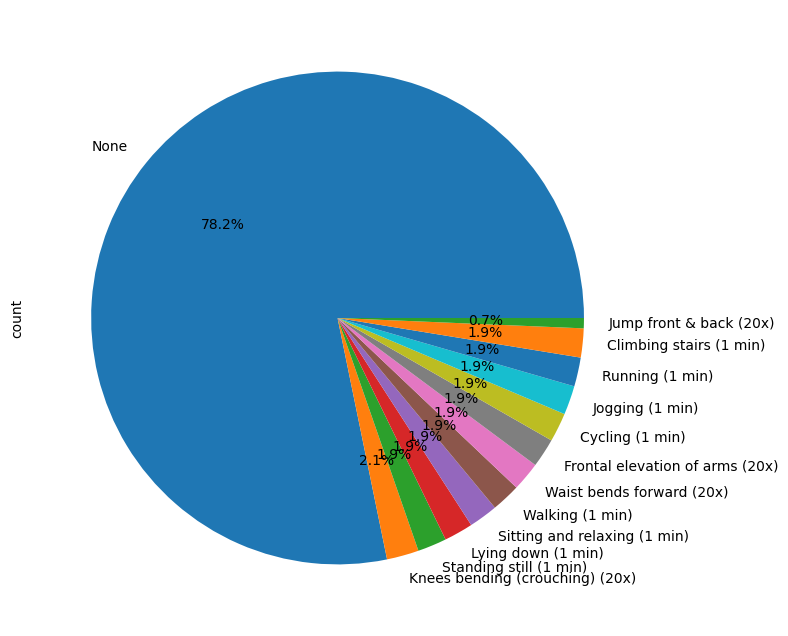

In [18]:
plt.figure(figsize=(12,8))
round(df["Label"].value_counts()/df.shape[0]*100,2).plot.pie(autopct= '%2.1f%%')

In [19]:
df1 = df.copy()

for feature in df1.columns[:-2]:
    lower_range = np.quantile(df[feature], 0.01)
    upper_range = np.quantile(df[feature], 0.99)
    print(feature, "range:", lower_range, 'to', upper_range)
    df1 = df1.drop(df1[(df1[feature] >upper_range) | (df1[feature] < lower_range)].index, axis = 0)
    print('shape', df1.shape)

acceleration from the chest sensor (X axis) range: nan to nan
shape (161281, 24)
acceleration from the chest sensor (Y axis) range: nan to nan
shape (161281, 24)
acceleration from the chest sensor (Z axis) range: nan to nan
shape (161281, 24)
electrocardiogram signal (lead 1) range: nan to nan
shape (161281, 24)
electrocardiogram signal (lead 2) range: nan to nan
shape (161281, 24)
acceleration from the left-ankle sensor (X axis) range: nan to nan
shape (161281, 24)
acceleration from the left-ankle sensor (Y axis) range: nan to nan
shape (161281, 24)
acceleration from the left-ankle sensor (Z axis) range: nan to nan
shape (161281, 24)
gyro from the left-ankle sensor (X axis) range: nan to nan
shape (161281, 24)
gyro from the left-ankle sensor (Y axis) range: nan to nan
shape (161281, 24)
gyro from the left-ankle sensor (Z axis) range: nan to nan
shape (161281, 24)
magnetometer from the left-ankle sensor (X axis) range: nan to nan
shape (161281, 24)
magnetometer from the left-ankle sens

In [20]:
df1

,acceleration from the chest sensor (X axis),acceleration from the chest sensor (Y axis),acceleration from the chest sensor (Z axis),electrocardiogram signal (lead 1),electrocardiogram signal (lead 2),acceleration from the left-ankle sensor (X axis),acceleration from the left-ankle sensor (Y axis),acceleration from the left-ankle sensor (Z axis),gyro from the left-ankle sensor (X axis),gyro from the left-ankle sensor (Y axis),...,acceleration from the right-lower-arm sensor (X axis),acceleration from the right-lower-arm sensor (Y axis),acceleration from the right-lower-arm sensor (Z axis),gyro from the right-lower-arm sensor (X axis),gyro from the right-lower-arm sensor (Y axis),gyro from the right-lower-arm sensor (Z axis),magnetometer from the right-lower-arm sensor (X axis),magnetometer from the right-lower-arm sensor (Y axis),magnetometer from the right-lower-arm sensor (Z axis),Label
0,-9.8184,0.009971,0.29563,0.004186,0.004186,2.1849,-9.6967,0.63077,0.103900,-0.84053,...,-8.6499,-4.57810,0.187760,-0.44902,-1.01030,0.034483,-2.35000,-1.610200,-0.030899,None
1,-9.8489,0.524040,0.37348,0.004186,0.016745,2.3876,-9.5080,0.68389,0.085343,-0.83865,...,-8.6275,-4.31980,0.023595,-0.44902,-1.01030,0.034483,-2.16320,-0.882540,0.326570,None
2,-9.6602,0.181850,0.43742,0.016745,0.037677,2.4086,-9.5674,0.68113,0.085343,-0.83865,...,-8.5055,-4.27720,0.275720,-0.44902,-1.01030,0.034483,-1.61750,-0.165620,-0.030693,None
3,-9.6507,0.214220,0.24033,0.079540,0.117220,2.1814,-9.4301,0.55031,0.085343,-0.83865,...,-8.6279,-4.31630,0.367520,-0.45686,-1.00820,0.025862,-1.07710,0.006945,-0.382620,None
4,-9.7030,0.303890,0.31156,0.221870,0.205130,2.4173,-9.3889,0.71098,0.085343,-0.83865,...,-8.7008,-4.14590,0.407290,-0.45686,-1.00820,0.025862,-0.53684,0.175900,-1.095500,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161276,-9.5201,0.751360,-3.84820,-0.104660,-0.025118,2.0773,-9.5717,2.24010,-0.903530,-0.96998,...,-4.4840,5.07440,6.441200,-0.65490,0.54415,0.676720,26.90100,-2.929500,-30.119000,None
161277,-9.3682,1.239600,-3.02530,-0.138150,-0.079540,1.7497,-9.3127,2.39560,-0.903530,-0.96998,...,-3.1657,0.98528,7.528400,-0.65490,0.54415,0.676720,17.28800,5.330800,-30.393000,None
161278,-8.6702,1.185900,-3.01960,-0.066981,-0.050235,1.8910,-9.3342,2.21890,-0.903530,-0.96998,...,-1.0351,-0.85876,6.123700,-0.65490,0.54415,0.676720,17.43000,19.502000,-28.727000,None
161279,-8.7211,1.205600,-2.00730,-0.012559,0.025118,2.3099,-9.2537,2.35210,-0.909090,-0.97186,...,-2.9315,-1.33840,5.162200,-0.65490,0.54415,0.676720,16.53500,19.779000,-20.084000,None


## Step 4: data preprocessing

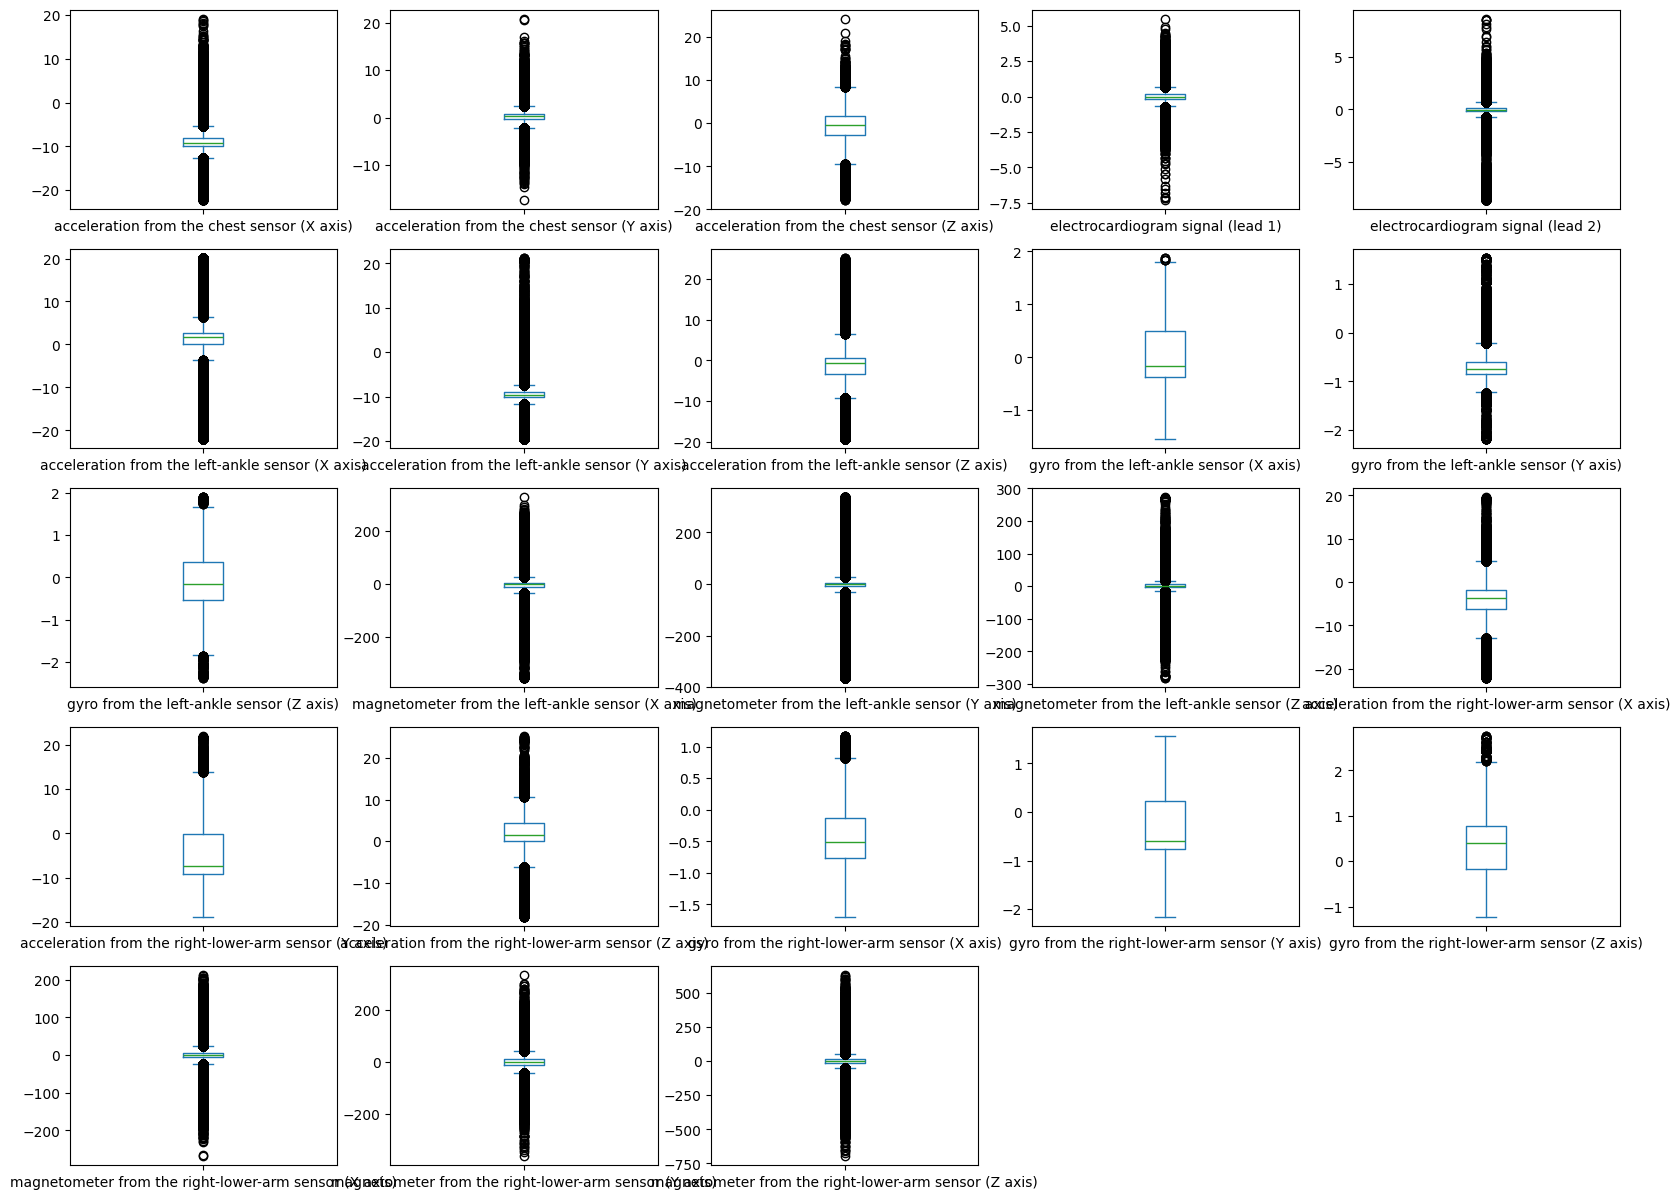

In [23]:
df.plot(kind='box', subplots=True, layout = (5,5), figsize=(20,15))
plt.show()

In [44]:
df = df.dropna()

In [45]:
X = df.drop(["Label"], axis=1).values
y = df["Label"].values

In [46]:
X_train,X_test,y_train,y_test = train_test_split(X, y,test_size=0.25)

In [47]:
ro_scaler = RobustScaler().fit(X_train)
X_train_scaled = ro_scaler.transform(X_train)
X_test_scaled=ro_scaler.transform(X_test)

## Step 5: Building Model

In [ ]:
def resultsSummarizer(y_true, y_pred, cm_en=True):
    cm = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro')
    rec = recall_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='macro')

    if cm_en:
        plt.figure(figsize=(15,15))
        sns.heatmap(cm, annot=True, cmap="Blues",
                    xticklabels=activity_label.values(),
                    yticklabels=activity_label.values())
        plt.title('Confusion Matrix') 
        plt.show()

    print(f'Accuracy Score: {acc:.4%}')
    print(f'Precision Score: {prec:.4%}')
    print(f'Recall Score: {rec:.4%}')
    print(f'F1 Score: {f1:.4%}')

## 1.Logistic Regression

In [49]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [50]:
lr.score(X_train, y_train)

0.8267609126984127

In [51]:
lr.score(X_test, y_test)

0.8259672619047619

In [ ]:
lr2 = LogisticRegression()
lr2.fit(X_train_scaled,y_train)

In [ ]:
lr2.score(X_train_scaled, y_train)

In [ ]:
lr2.score(X_test_scaled, y_test)

In [ ]:
y_pred_lr = lr2.predict(X_test_scaled)

In [52]:
y_pred_lr = lr.predict(X_test)

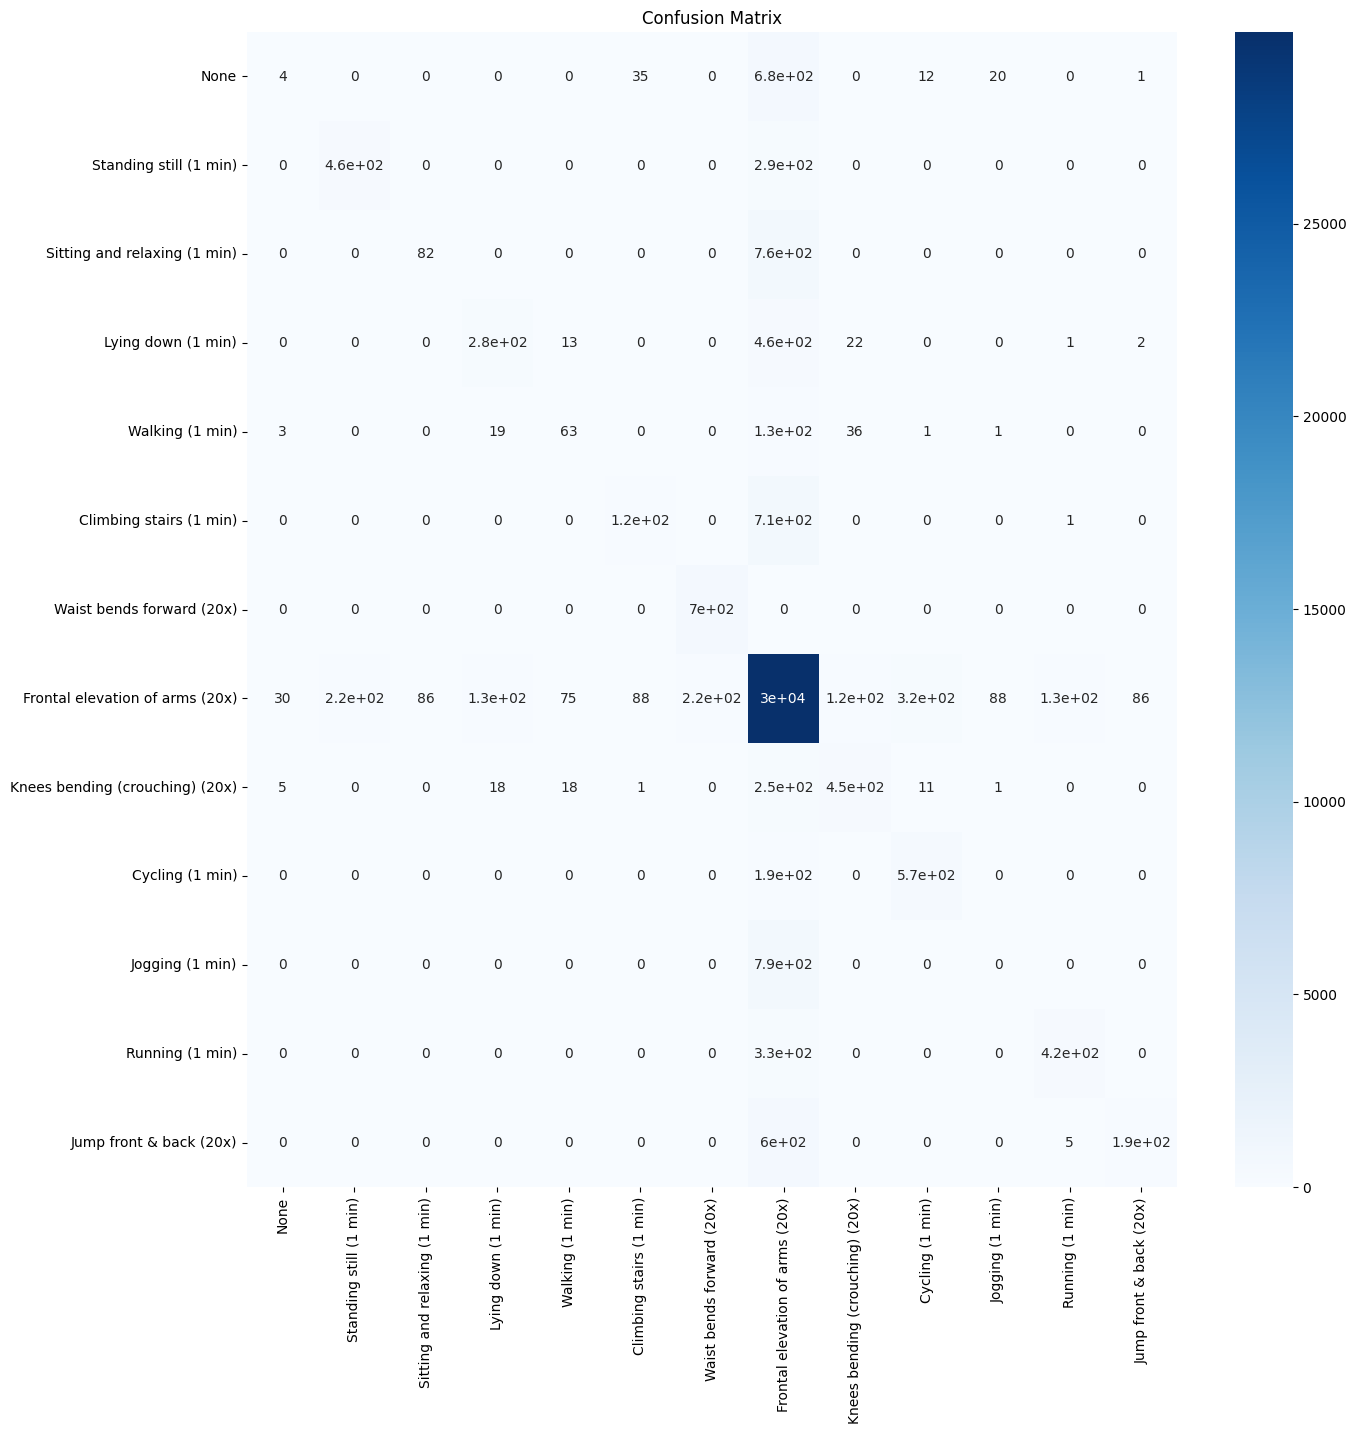

Accuracy Score: 82.5967%
Precision Score: 54.9276%
Recall Score: 42.7217%
F1 Score: 45.2157%


In [53]:
resultsSummarizer(y_test, y_pred_lr)

## 2.KNN

In [54]:
knn1 = KNeighborsClassifier(n_neighbors=5)
knn1.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](13,)","['Climbing stairs (1 min)','Cycling (1 min)', 'Frontal elevation of arms (20x)',...,'Standing still (1 min)', 'Waist bends forward (20x)','Walking (1 min)']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [55]:
y_pred_knn = knn1.predict(X_test)

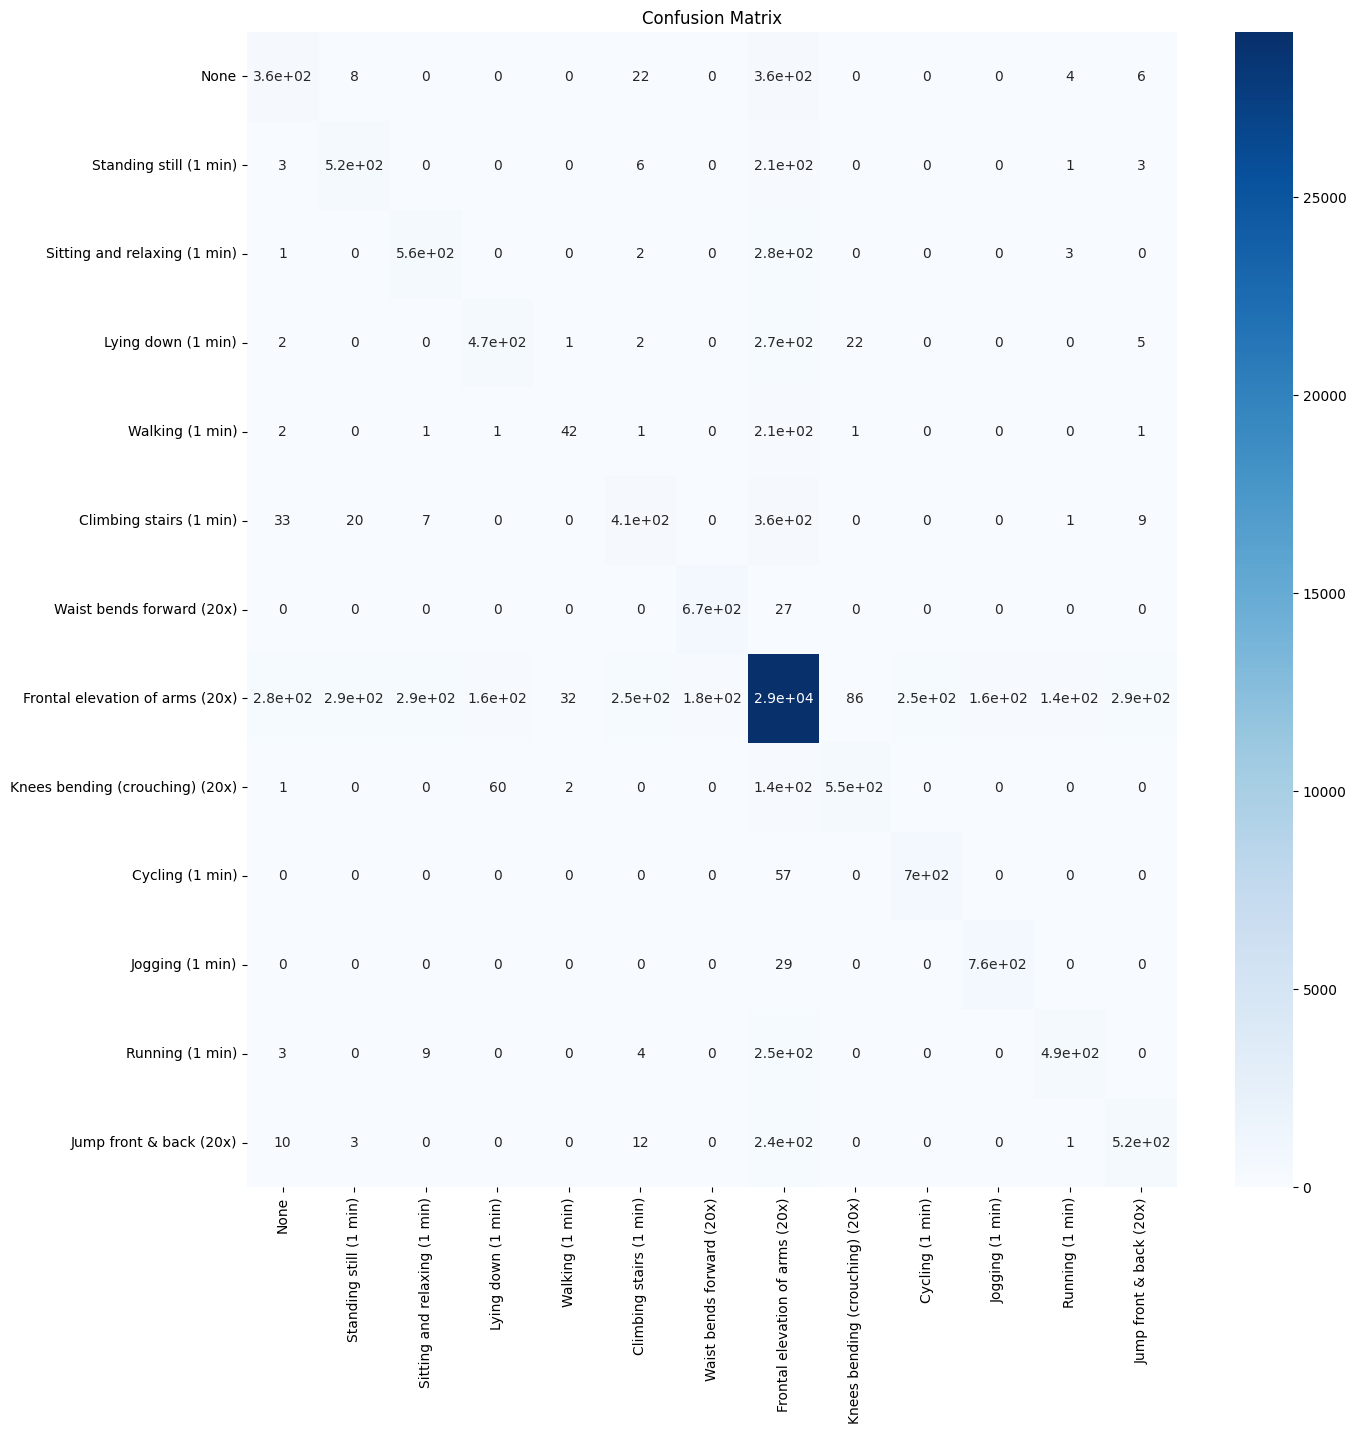

Accuracy Score: 87.3413%
Precision Score: 69.9286%
Recall Score: 68.5030%
F1 Score: 68.1037%


In [56]:
resultsSummarizer(y_test, y_pred_knn)

In [57]:
knn2 = KNeighborsClassifier(n_neighbors=5)
knn2.fit(X_train_scaled, y_train)
y_pred_knn2 = knn2.predict(X_test_scaled)


In [58]:
resultsSummarizer(y_test, y_pred_knn2, cm_en=False)

Accuracy Score: 93.5863%
Precision Score: 82.8493%
Recall Score: 88.4140%
F1 Score: 85.0507%


In [59]:
for n in range(1,11):
    knn  = KNeighborsClassifier(n_neighbors=n) 
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled) 
    print(f"\n==============No of Neighbors: {n}=====================\n")
    resultsSummarizer(y_test, y_pred, cm_en=False)


==============No of Neighbors: 1=====================

Accuracy Score: 93.7525%
Precision Score: 84.3711%
Recall Score: 86.7719%
F1 Score: 85.4903%

==============No of Neighbors: 2=====================

Accuracy Score: 92.7505%
Precision Score: 81.4270%
Recall Score: 87.2628%
F1 Score: 83.6900%

==============No of Neighbors: 3=====================

Accuracy Score: 93.9062%
Precision Score: 83.7052%
Recall Score: 88.5226%
F1 Score: 85.7835%

==============No of Neighbors: 4=====================

Accuracy Score: 93.3185%
Precision Score: 81.8545%
Recall Score: 89.1751%
F1 Score: 85.0374%

==============No of Neighbors: 5=====================

Accuracy Score: 93.5863%
Precision Score: 82.8493%
Recall Score: 88.4140%
F1 Score: 85.0507%

==============No of Neighbors: 6=====================

Accuracy Score: 93.3085%
Precision Score: 81.6417%
Recall Score: 89.3100%
F1 Score: 84.8991%

==============No of Neighbors: 7=====================

Accuracy Score: 93.3383%
Precision Score: 82.2845%

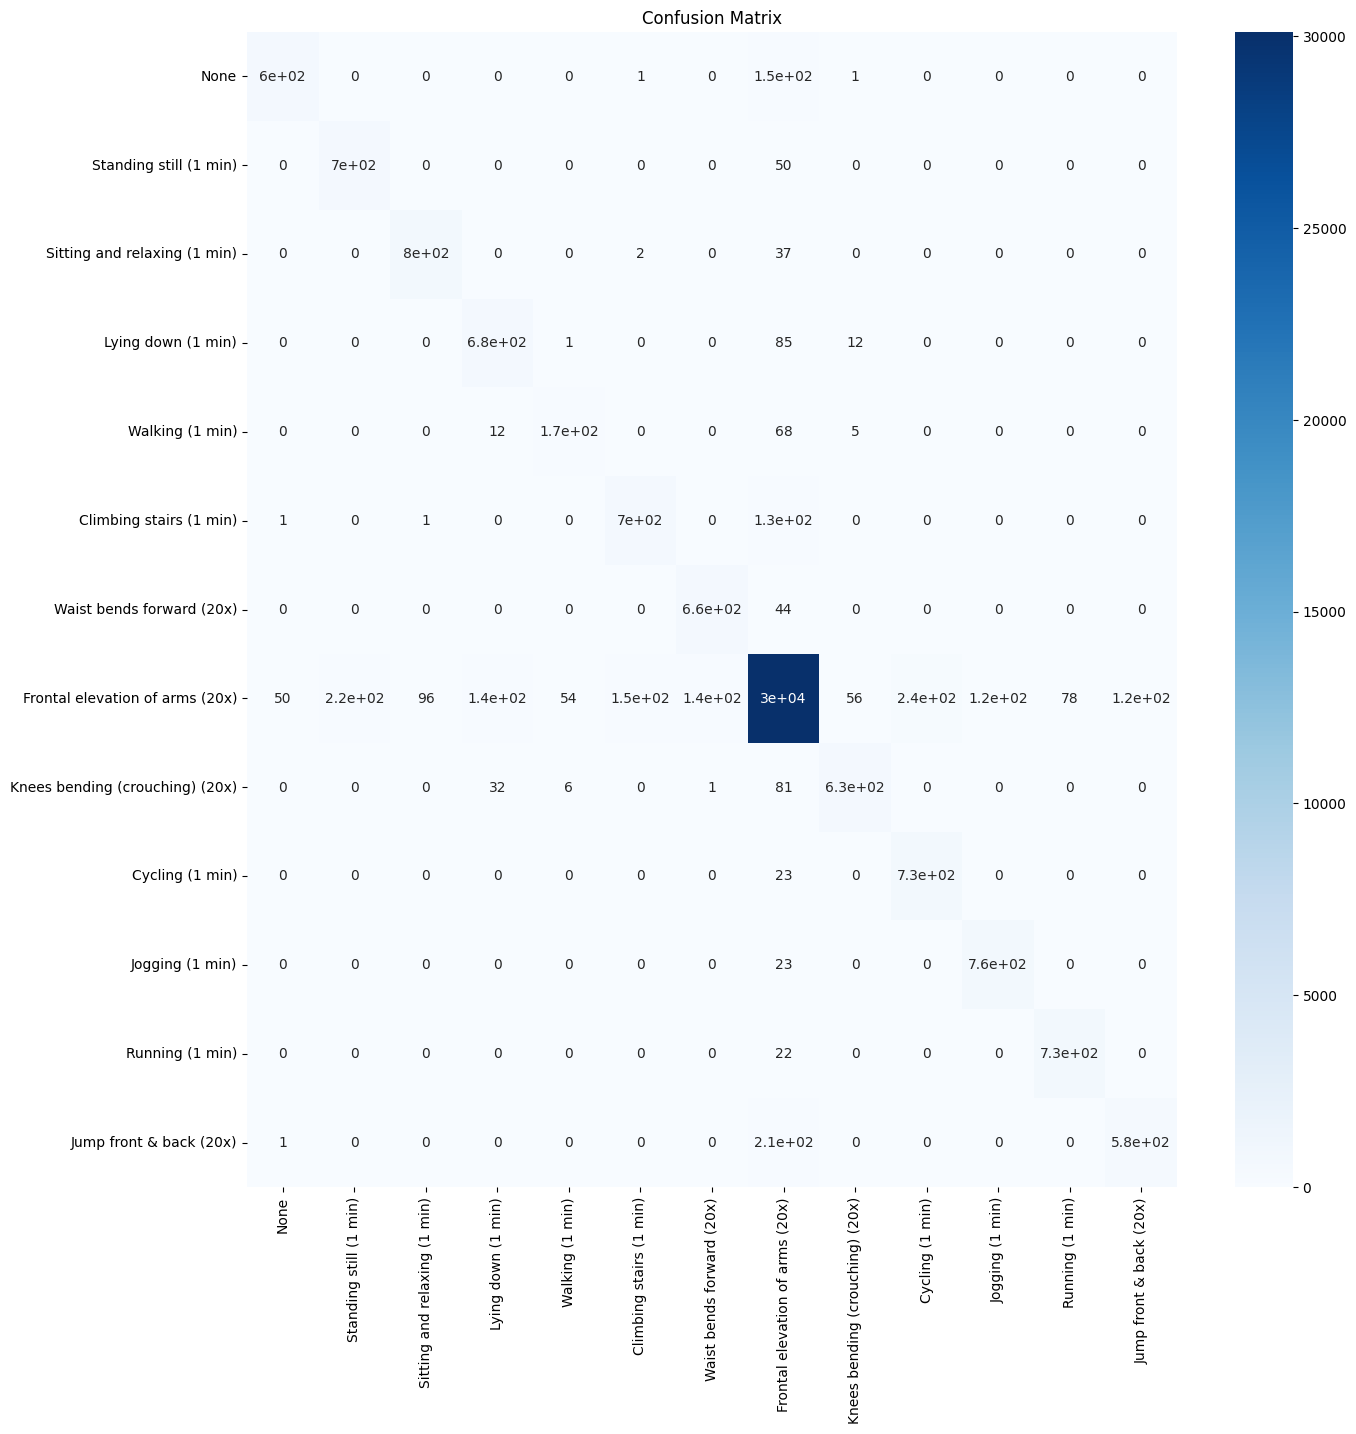

Accuracy Score: 93.9062%
Precision Score: 84.3420%
Recall Score: 88.0420%
F1 Score: 85.8601%


In [60]:
dt = DecisionTreeClassifier(max_depth=14)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
resultsSummarizer(y_test, y_pred_dt)

In [61]:
sample = X_test[0].reshape(1, -1)

prediction = lr.predict(sample)

print(prediction)

['None']


In [62]:
for i in range(20):
    sample = X_test[i].reshape(1,-1)
    pred = lr.predict(sample)
    print(i, pred)

0 ['None']
1 ['None']
2 ['None']
3 ['Sitting and relaxing (1 min)']
4 ['None']
5 ['Cycling (1 min)']
6 ['None']
7 ['None']
8 ['None']
9 ['Running (1 min)']
10 ['None']
11 ['Jogging (1 min)']
12 ['None']
13 ['None']
14 ['None']
15 ['None']
16 ['None']
17 ['Sitting and relaxing (1 min)']
18 ['None']
19 ['None']


In [68]:
df = df[df["Label"] != "None"]

In [69]:
X = df.drop(["Label"], axis=1).values
y = df["Label"].values

In [70]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [73]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)
lr.fit(X_train, y_train)

C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [74]:
y_pred_lr = lr.predict(X_test)

print(y_pred_lr[:10])

['Standing still (1 min)' 'Lying down (1 min)' 'Jogging (1 min)'
 'Running (1 min)' 'Frontal elevation of arms (20x)'
 'Standing still (1 min)' 'Waist bends forward (20x)'
 'Sitting and relaxing (1 min)' 'Walking (1 min)' 'Walking (1 min)']


In [75]:
sample = X_test[3].reshape(1,-1)

prediction = lr.predict(sample)

print("Predicted Activity:", prediction[0])

Predicted Activity: Running (1 min)


In [76]:
sample = X_test[4].reshape(1,-1)

prediction = lr.predict(sample)

print("Predicted Activity:", prediction[0])

Predicted Activity: Frontal elevation of arms (20x)


In [1]:
print("hello")

hello


In [1]:
import pickle

pickle.dump(lr, open("model.pkl", "wb"))

print("Model Saved Successfully")

NameError: name 'lr' is not defined

In [3]:
print(type(lr))

NameError: name 'lr' is not defined

In [4]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)

lr.fit(X_train, y_train)

print("Model Trained")

NameError: name 'X_train' is not defined

In [2]:
import pandas as pd

df = pd.read_csv("mHealth_subject1.csv")

print(df.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'mHealth_subject1.csv'

In [3]:
import os

print(os.getcwd())

C:\Users\LENOVO\Human Action


In [4]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'app.py', 'data', 'Human Action Detection (1).ipynb', 'streamlit']


In [5]:
import os

for f in os.listdir():
    print(f)

.ipynb_checkpoints
app.py
data
Human Action Detection (1).ipynb
streamlit


In [6]:
import os

print(os.listdir("data"))

['mHealth_subject1.csv', 'mHealth_subject10.csv', 'mHealth_subject2.csv', 'mHealth_subject3.csv', 'mHealth_subject4.csv', 'mHealth_subject5.csv', 'mHealth_subject6.csv', 'mHealth_subject7.csv', 'mHealth_subject8.csv', 'mHealth_subject9.csv']


In [7]:
import pandas as pd

df = pd.read_csv("data/mHealth_subject1.csv")

print(df.shape)

(161281, 24)


In [8]:
X = df.drop("Label", axis=1)
y = df["Label"]

print(X.shape)
print(y.shape)

(161281, 23)
(161281,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(120960, 23)
(40321, 23)


In [10]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)

lr.fit(X_train, y_train)

print("Model Trained Successfully")

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [11]:
print(df.isna().sum().sum())

24


In [12]:
df = df.dropna()

print(df.isna().sum().sum())
print(df.shape)

0
(161280, 24)


In [13]:
X = df.drop("Label", axis=1)
y = df["Label"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)

lr.fit(X_train, y_train)

print("Model Trained Successfully")

Model Trained Successfully


C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [14]:
import pickle

pickle.dump(lr, open("model.pkl", "wb"))

print("Model Saved Successfully")

Model Saved Successfully


In [15]:
import pickle

model = pickle.load(open("model.pkl", "rb"))
print(type(model))
print(model.classes_)

<class 'sklearn.linear_model._logistic.LogisticRegression'>
[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]


In [16]:
import pandas as pd

df = pd.read_csv("data/mHealth_subject1.csv")

print(df["Label"].value_counts().sort_index())

Label
0.0     126106
1.0       3072
2.0       3072
3.0       3072
4.0       3072
5.0       3072
6.0       3072
7.0       3072
8.0       3379
9.0       3072
10.0      3072
11.0      3072
12.0      1075
Name: count, dtype: int64


In [17]:
df = pd.read_csv("data/mHealth_subject1.csv")

df = df[df["Label"] != 0]

print(df["Label"].value_counts())

Label
8.0     3379
1.0     3072
3.0     3072
2.0     3072
4.0     3072
6.0     3072
7.0     3072
9.0     3072
10.0    3072
11.0    3072
5.0     3072
12.0    1075
Name: count, dtype: int64


In [20]:
df = df.dropna()

X = df.drop("Label", axis=1)
y = df["Label"]

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

In [24]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)

lr.fit(X_train, y_train)

C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [25]:
import pandas as pd

df = pd.read_csv("data/mHealth_subject1.csv")

df = df[df["Label"] != 0]

df = df.dropna()

X = df.drop("Label", axis=1)
y = df["Label"]

In [26]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)

lr.fit(X_train, y_train)

print("Model Trained")

Model Trained


C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [27]:
import pickle

pickle.dump(lr, open("model.pkl", "wb"))

print("Model Saved Successfully")

Model Saved Successfully


In [1]:
import pandas as pd

df = pd.read_csv("data/mHealth_subject1.csv")

print(df.columns.tolist())

['acceleration from the chest sensor (X axis)', 'acceleration from the chest sensor (Y axis)', 'acceleration from the chest sensor (Z axis)', 'electrocardiogram signal (lead 1)', 'electrocardiogram signal (lead 2)', 'acceleration from the left-ankle sensor (X axis)', 'acceleration from the left-ankle sensor (Y axis)', 'acceleration from the left-ankle sensor (Z axis)', 'gyro from the left-ankle sensor (X axis)', 'gyro from the left-ankle sensor (Y axis)', 'gyro from the left-ankle sensor (Z axis)', 'magnetometer from the left-ankle sensor (X axis)', 'magnetometer from the left-ankle sensor (Y axis)', 'magnetometer from the left-ankle sensor (Z axis)', 'acceleration from the right-lower-arm sensor (X axis)', 'acceleration from the right-lower-arm sensor (Y axis)', 'acceleration from the right-lower-arm sensor (Z axis)', 'gyro from the right-lower-arm sensor (X axis)', 'gyro from the right-lower-arm sensor (Y axis)', 'gyro from the right-lower-arm sensor (Z axis)', 'magnetometer from the

In [2]:
import pandas as pd

df = pd.read_csv("data/mHealth_subject1.csv")

print(df[df["Label"] != 0].shape)

(35175, 24)
